In [28]:
from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np
import yaml

In [29]:
def get_cardinality_distribution(query_results_path: Path) -> tuple[pd.DataFrame, int]:
    with open(query_results_path, 'r') as f:
        query_results = json.load(f)
    
    num_queries = len(query_results)
    cardinalities = [result['y'] for result in query_results]
    distribution = pd.Series(cardinalities).value_counts().sort_index()
    
    return distribution, num_queries

In [30]:
# Load dataset configurations from experiments_config.yaml
config_path = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/benchmarks/gcare/experiments_config.yaml")
with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

# Create a mapping of datasets by name
datasets = {}
for exp in config['experiments']:
    dataset_name = exp['name']
    datasets[dataset_name] = {
        'dataset': exp['dataset_name'],
        'query_type': exp['query_type'],
        'query_path': Path(exp['query_path']),
        'graph_path': Path(exp['graph_path']),
        'num_queries': exp.get('num_queries', 500)
    }

# Print available datasets
print("Available datasets:")
for i, name in enumerate(datasets.keys(), 1):
    exp = datasets[name]
    print(f"  {i}. {name:30s} ({exp['dataset']:15s} - {exp['query_type']})")
print(f"\nTotal: {len(datasets)} dataset configurations")

Available datasets:
  1. wikidata_path                  (wikidata        - path)
  2. wikidata_star                  (wikidata        - star)

Total: 2 dataset configurations


In [31]:
# ========== DATASET SELECTOR ==========
# Choose which datasets to analyze by setting the names from the config
# Available: 'wikidata_path', 'wikidata_star' (see list above for all options)

SELECTED_STAR_DATASET = 'wikidata_star'
SELECTED_PATH_DATASET = 'wikidata_path'

# Get the paths from the configuration
star_queries_path = datasets[SELECTED_STAR_DATASET]['query_path']
path_queries_path = datasets[SELECTED_PATH_DATASET]['query_path']

print(f"Selected star dataset: {SELECTED_STAR_DATASET}")
print(f"  Path: {star_queries_path}")
print(f"\nSelected path dataset: {SELECTED_PATH_DATASET}")
print(f"  Path: {path_queries_path}")

Selected star dataset: wikidata_star
  Path: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/wikidata_queries/raw/59320583

Selected path dataset: wikidata_path
  Path: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/wikidata_path_queries/raw/60037220?private_link=435c4febc01f57ca3b6d


In [32]:
# Load cardinality distributions
star_distribution, num_star_queries = get_cardinality_distribution(star_queries_path)
path_distribution, num_path_queries = get_cardinality_distribution(path_queries_path)

print(f"Star queries: {num_star_queries} total queries, {len(star_distribution)} unique cardinalities")
print(f"Path queries: {num_path_queries} total queries, {len(path_distribution)} unique cardinalities")

Star queries: 109545 total queries, 12773 unique cardinalities
Path queries: 101313 total queries, 11613 unique cardinalities


In [33]:
# Extract cardinality values for histogram (in logspace)
with open(star_queries_path, 'r') as f:
    star_queries = json.load(f)
star_cardinalities = [np.log10(result['y'] + 1) for result in star_queries]

with open(path_queries_path, 'r') as f:
    path_queries = json.load(f)
path_cardinalities = [np.log10(result['y'] + 1) for result in path_queries]

print(f"Star queries loaded: {len(star_cardinalities)}")
print(f"Path queries loaded: {len(path_cardinalities)}")

Star queries loaded: 109545
Path queries loaded: 101313


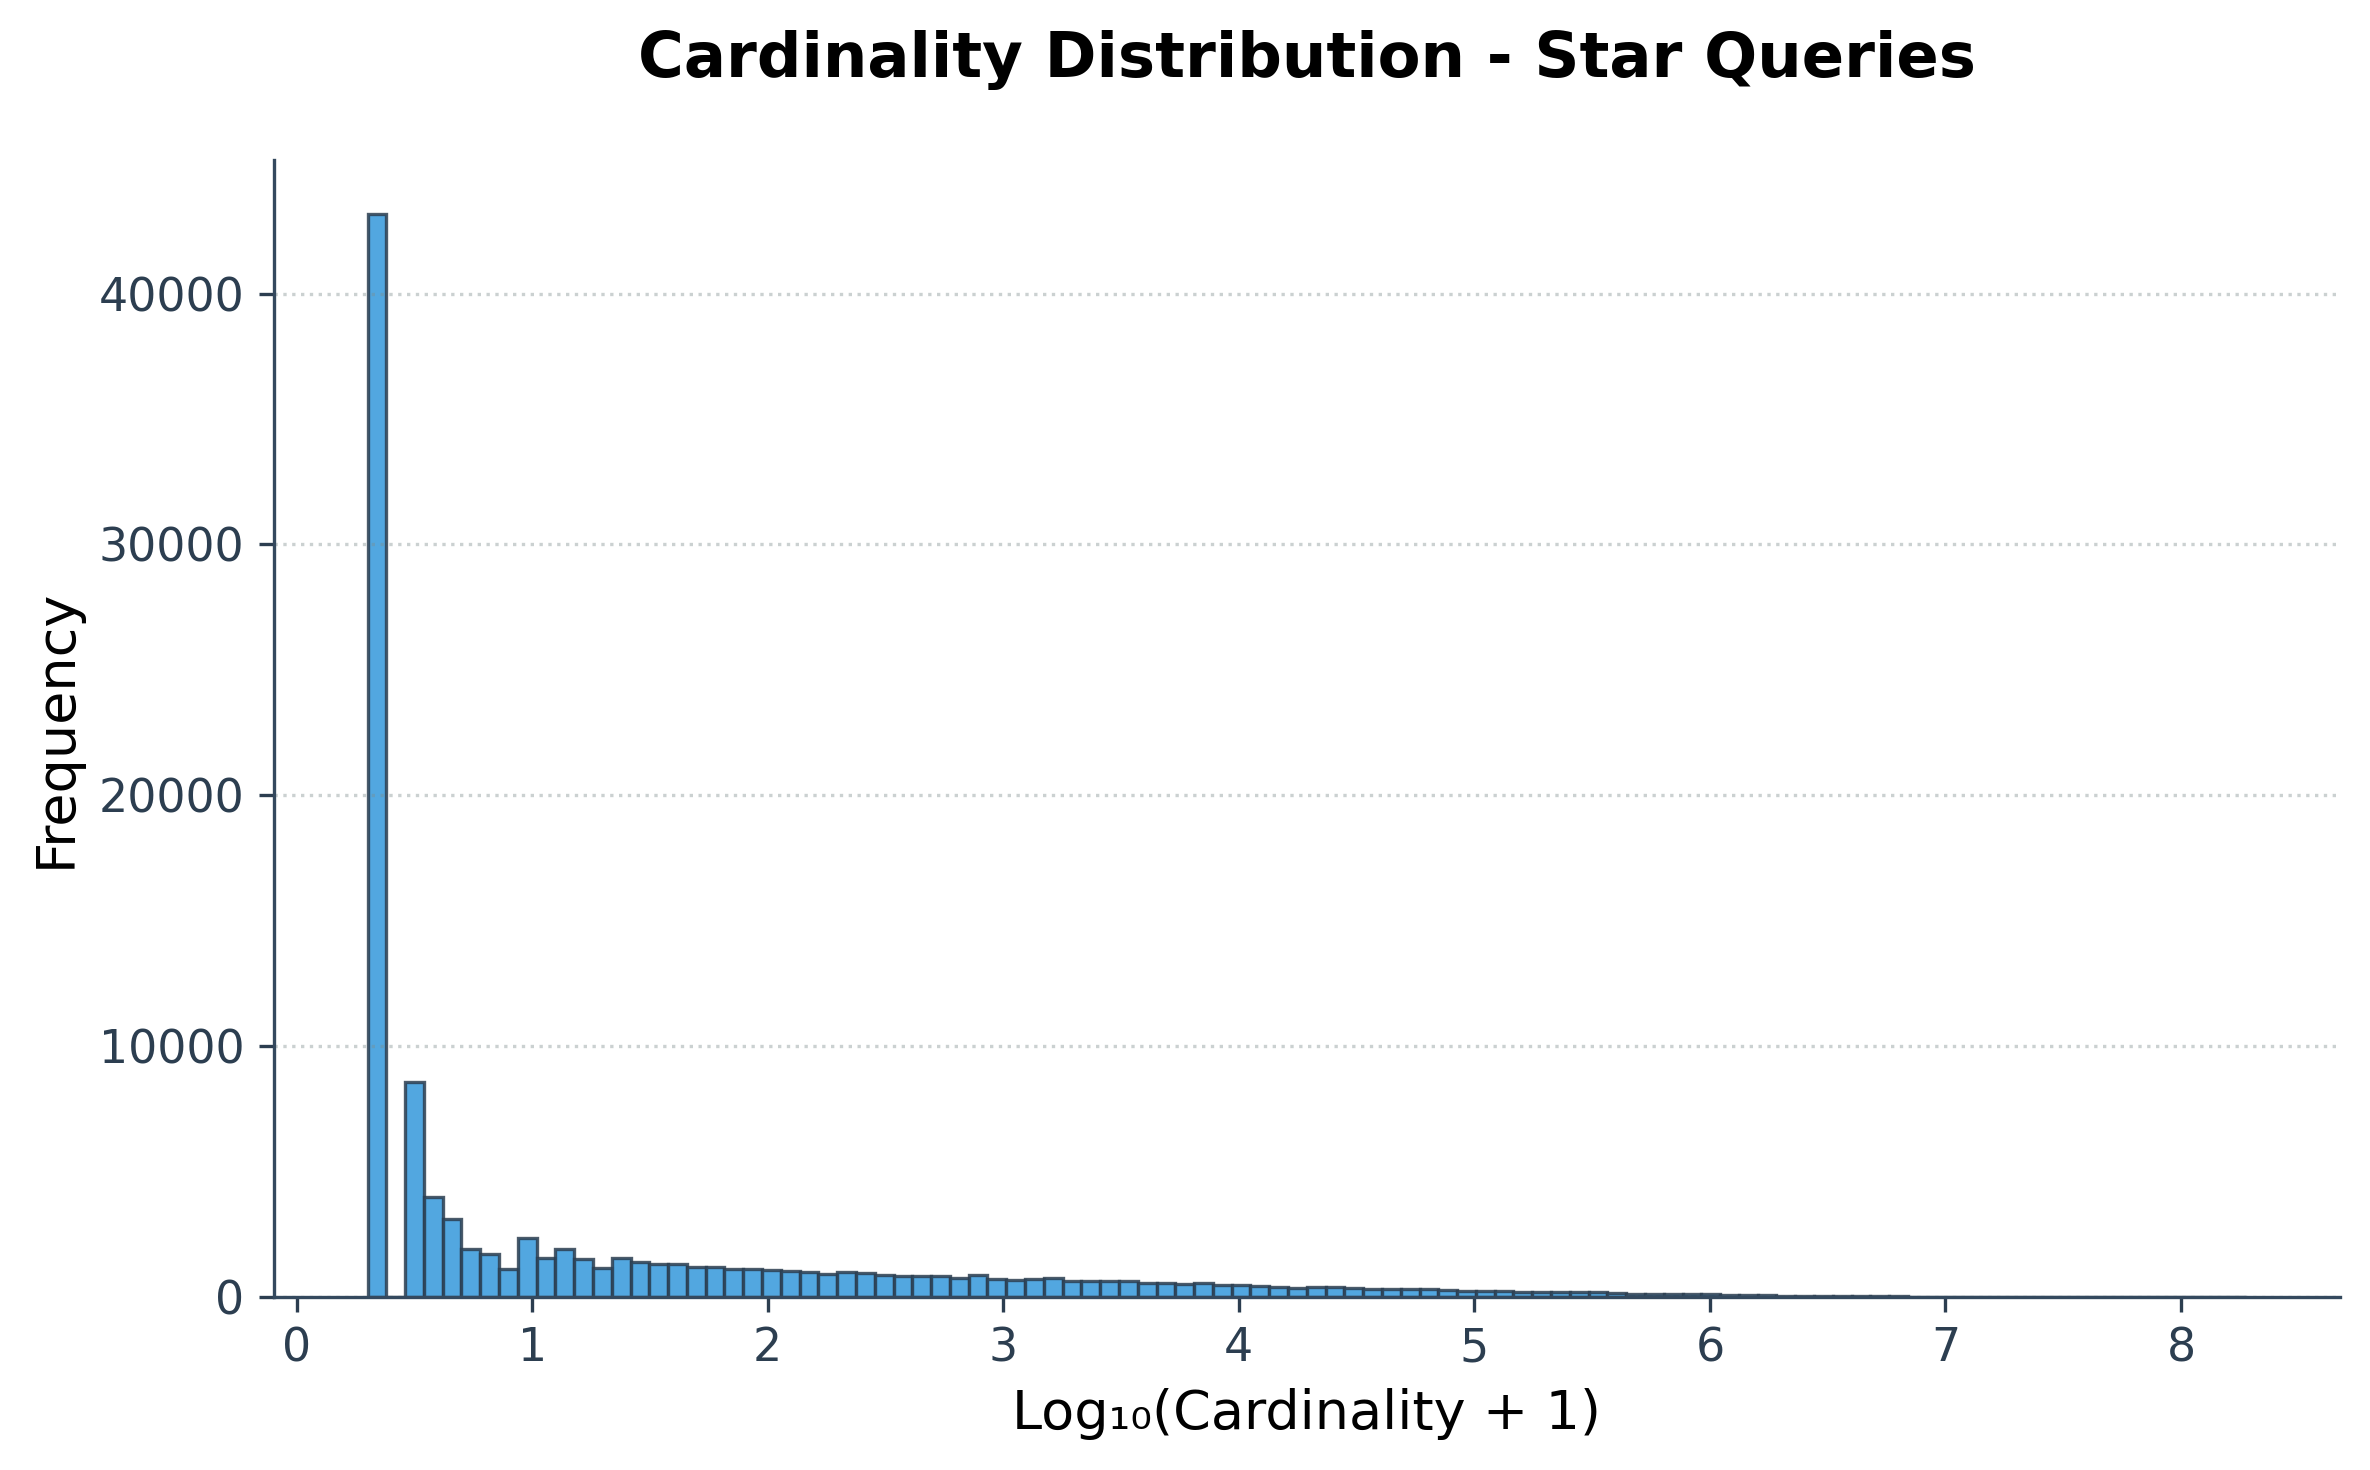

Saved: star_queries_cardinality_distribution.pdf


In [34]:
# Create histogram for star queries
plt.style.use('default')
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

ax.hist(star_cardinalities, bins=100, color='#3498db', edgecolor='#2c3e50', 
        alpha=0.85, linewidth=0.8)
ax.set_xlabel('Log₁₀(Cardinality + 1)', fontsize=13)
ax.set_ylabel('Frequency', fontsize=13)
ax.set_title('Cardinality Distribution - Star Queries', fontsize=15, 
             fontweight='bold', pad=20)

# Styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#34495e')
ax.spines['bottom'].set_color('#34495e')
ax.grid(axis='y', linestyle=':', alpha=0.4, color='#7f8c8d')
ax.tick_params(labelsize=11, colors='#2c3e50')

plt.tight_layout()
plt.savefig('star_queries_cardinality_distribution.pdf', bbox_inches='tight', dpi=300)
plt.show()

print("Saved: star_queries_cardinality_distribution.pdf")

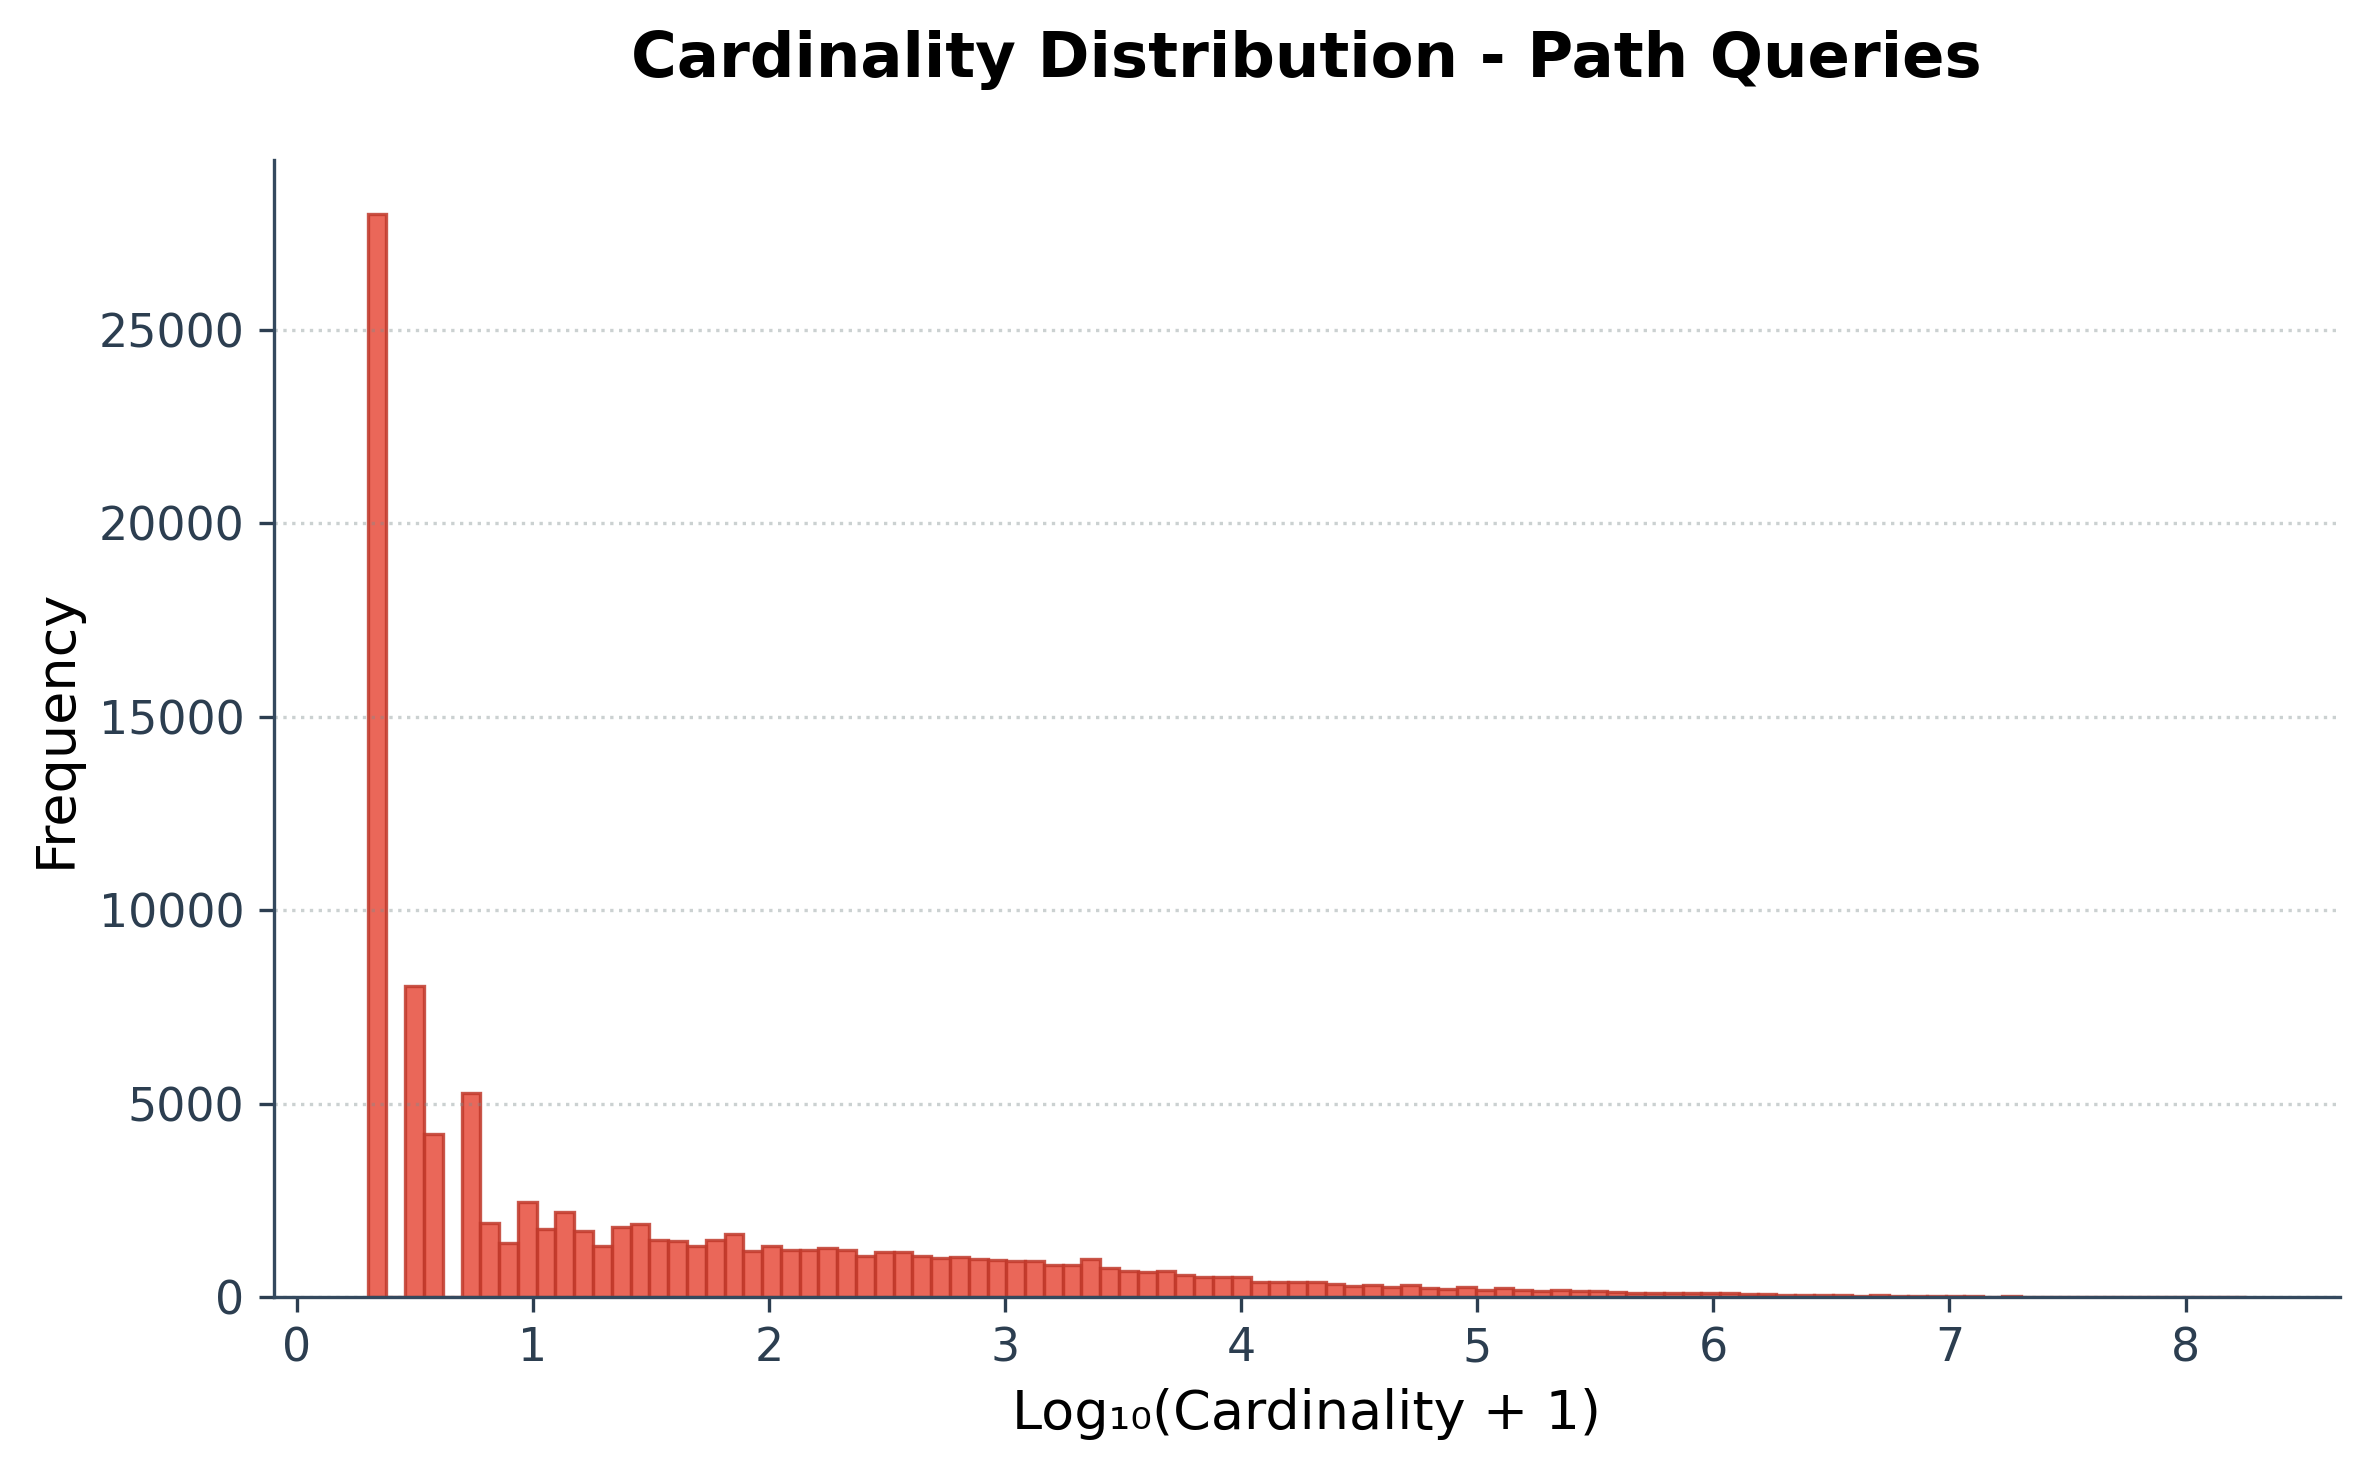

Saved: path_queries_cardinality_distribution.pdf


In [35]:
# Create histogram for path queries
plt.style.use('default')
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

ax.hist(path_cardinalities, bins=100, color='#e74c3c', edgecolor='#c0392b', 
        alpha=0.85, linewidth=0.8)
ax.set_xlabel('Log₁₀(Cardinality + 1)', fontsize=13)
ax.set_ylabel('Frequency', fontsize=13)
ax.set_title('Cardinality Distribution - Path Queries', fontsize=15, 
             fontweight='bold', pad=20)

# Styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#34495e')
ax.spines['bottom'].set_color('#34495e')
ax.grid(axis='y', linestyle=':', alpha=0.4, color='#7f8c8d')
ax.tick_params(labelsize=11, colors='#2c3e50')

plt.tight_layout()
plt.savefig('path_queries_cardinality_distribution.pdf', bbox_inches='tight', dpi=300)
plt.show()

print("Saved: path_queries_cardinality_distribution.pdf")

In [36]:
# Find all query datasets in the data folder
import os

data_dir = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data")

# Collect all cardinalities from all query datasets
all_cardinalities = []
dataset_info = []

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir() and ('queries' in folder.name or 'query' in folder.name or 'path' in folder.name or 'star' in folder.name):
        # Look for query files in raw/ subfolder
        raw_folder = folder / 'raw'
        if raw_folder.exists():
            for query_file in raw_folder.iterdir():
                if query_file.is_file() and not query_file.name.startswith('.'):
                    try:
                        with open(query_file, 'r') as f:
                            queries = json.load(f)
                            cardinalities = [np.log10(result['y'] + 1) for result in queries]
                            all_cardinalities.extend(cardinalities)
                            dataset_info.append({
                                'dataset': folder.name,
                                'file': query_file.name,
                                'count': len(cardinalities)
                            })
                            print(f"Loaded {len(cardinalities)} queries from {folder.name}/{query_file.name}")
                    except Exception as e:
                        print(f"Error loading {folder.name}/{query_file.name}: {e}")

print(f"\nTotal queries loaded: {len(all_cardinalities)}")
print(f"Total datasets: {len(dataset_info)}")

Loaded 49458 queries from dbpedia100k_path_queries/59898644?private_link=d6411dc19831edc2f780
Loaded 44290 queries from dbpedia100k_star_queries/59687708?private_link=1e23a3388a4b6b6161d1
Loaded 21356 queries from fb237_v4_ind_path_queries/59900708?private_link=103743702bc11e9b4672
Loaded 41654 queries from fb237_v4_ind_star_queries/59731859?private_link=953281688dbdb230c09d
Loaded 32728 queries from fb237_v4_path_queries/59900678?private_link=69c356b2701ace402cf9
Loaded 41491 queries from fb237_v4_star_queries/59651327?private_link=780ccfbe4856b223d7b5
Loaded 55336 queries from lubm_path_queries/60037037?private_link=8e4493e070acfd065b77
Loaded 113855 queries from lubm_queries/59410580
Loaded 116709 queries from swdf_path_queries/60037112?private_link=81b137c60854d11ee270
Loaded 116645 queries from swdf_star_queries/59320652
Loaded 101313 queries from wikidata_path_queries/60037220?private_link=435c4febc01f57ca3b6d
Loaded 109545 queries from wikidata_queries/59320583
Loaded 34812 quer

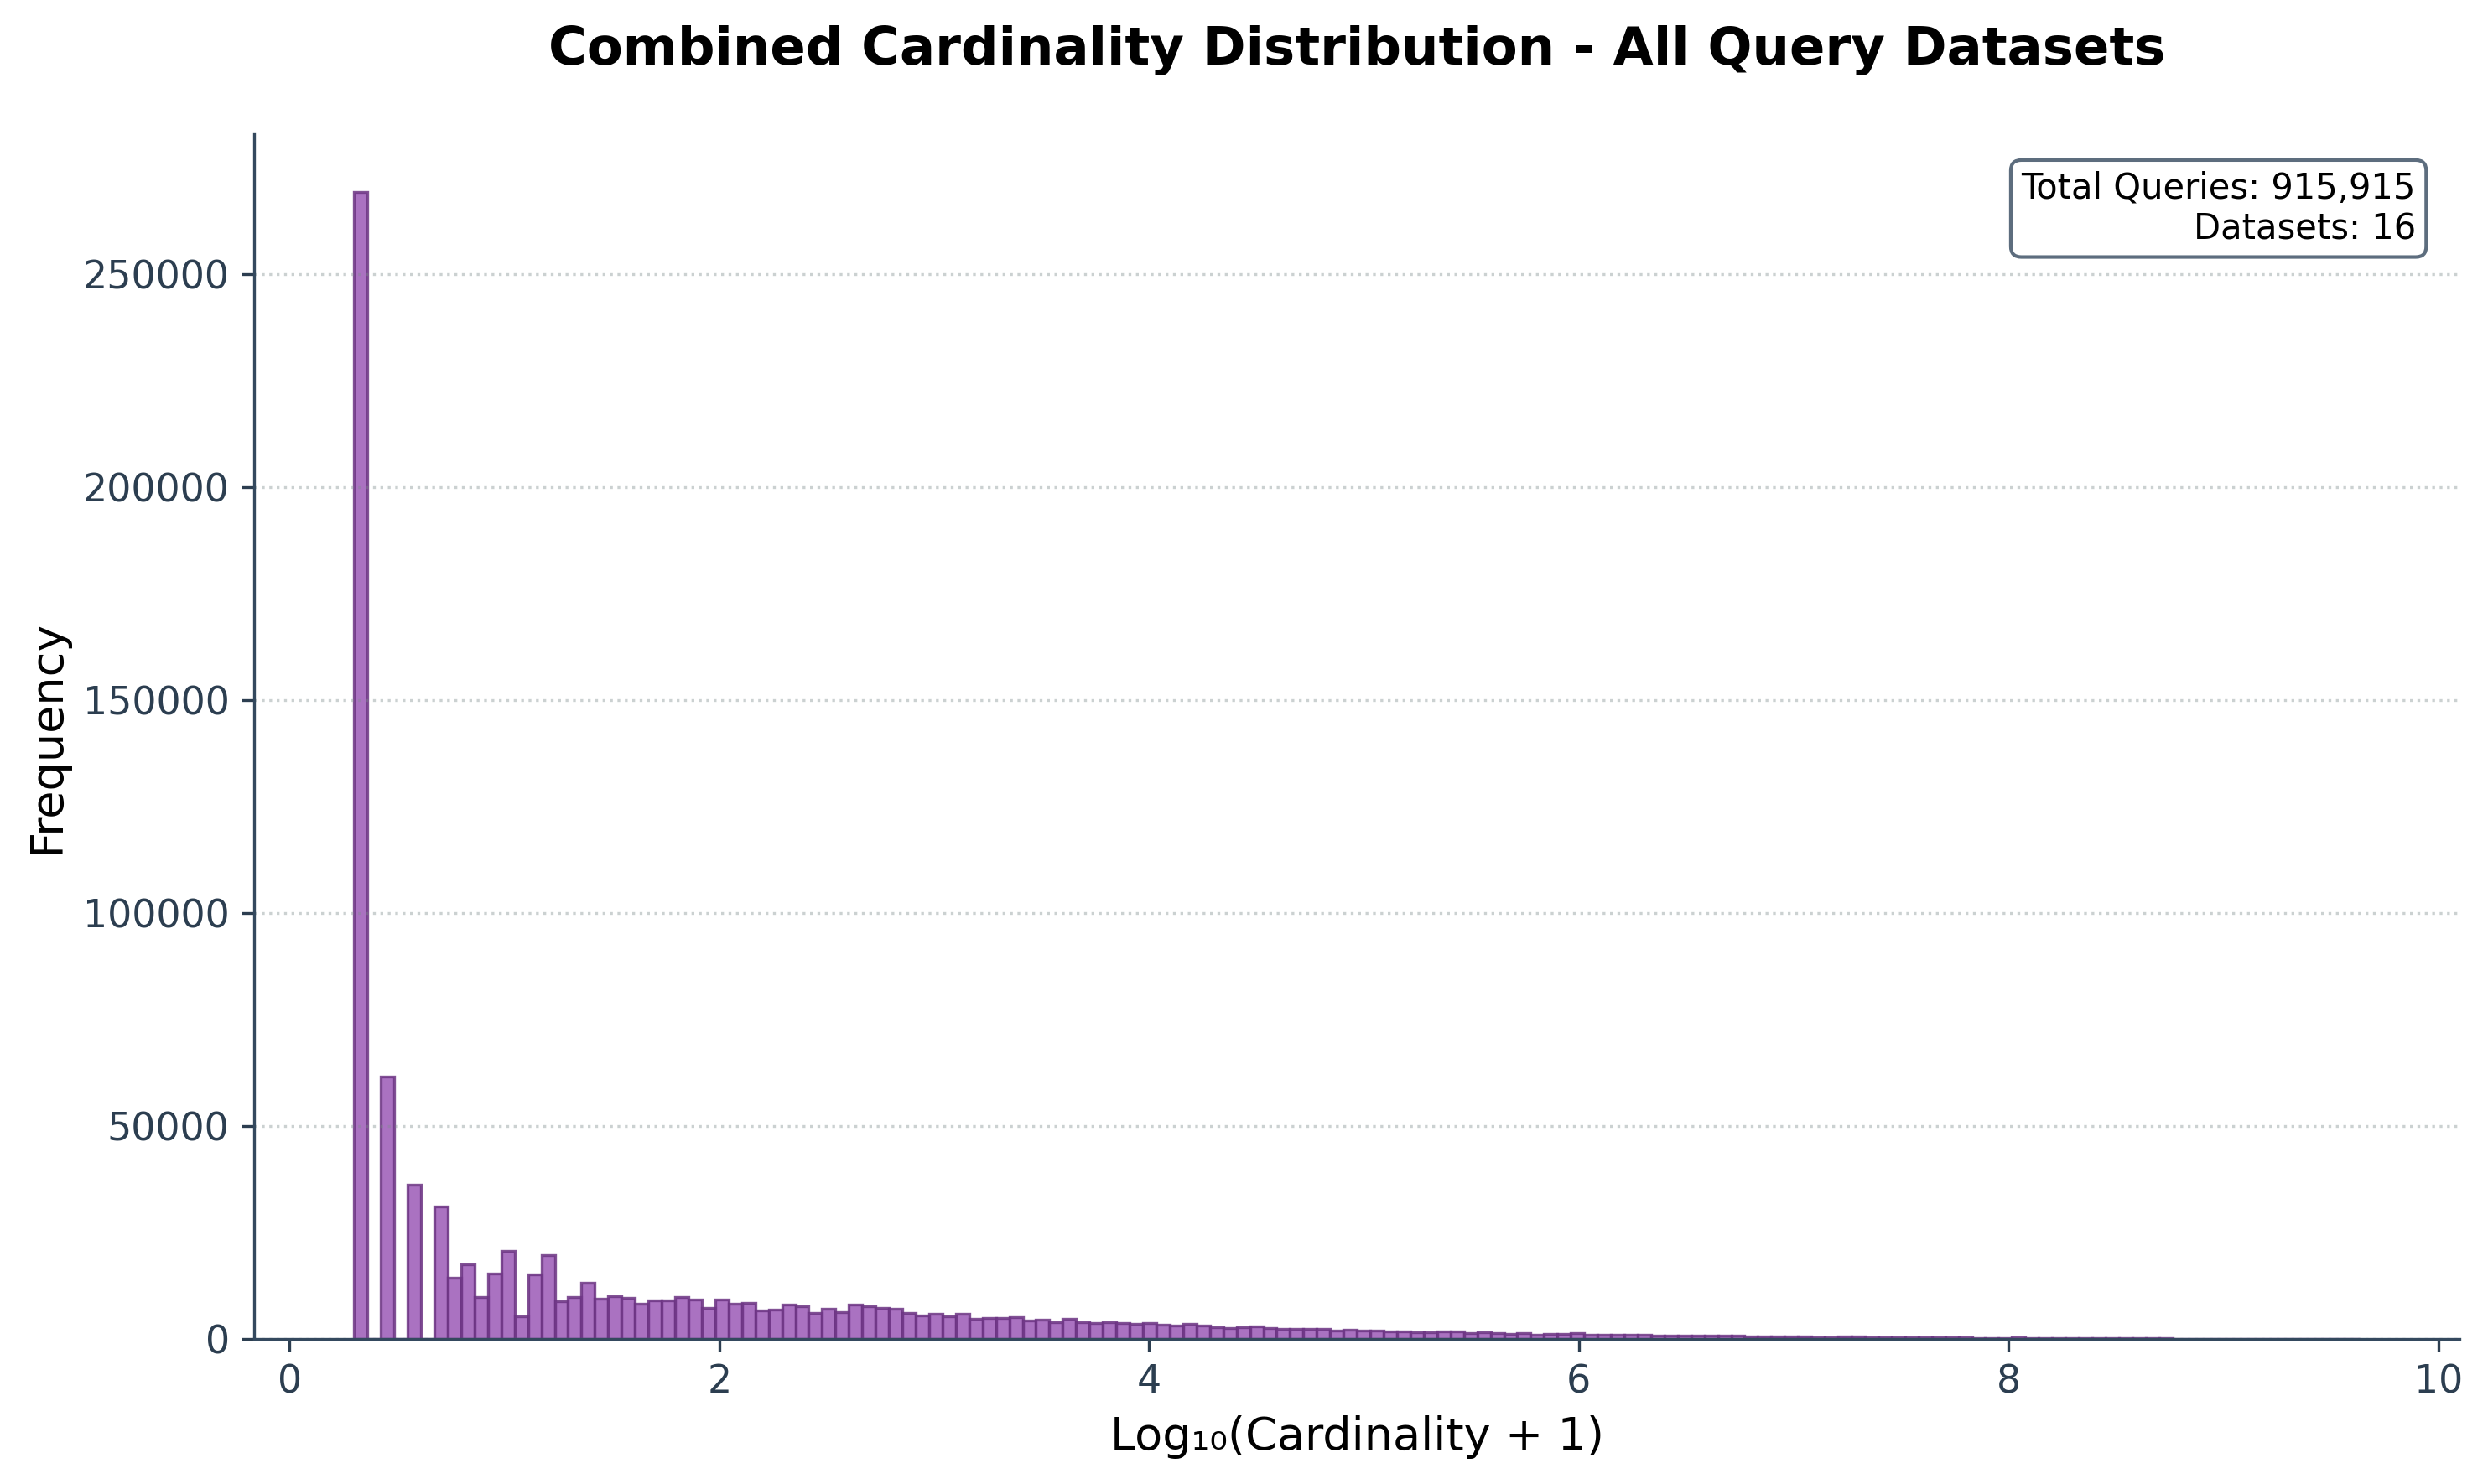

Saved: combined_cardinality_distribution.pdf


In [37]:
# Create combined histogram for all query datasets
plt.style.use('default')
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

ax.hist(all_cardinalities, bins=150, color='#9b59b6', edgecolor='#6c3483', 
        alpha=0.85, linewidth=0.8)
ax.set_xlabel('Log₁₀(Cardinality + 1)', fontsize=13)
ax.set_ylabel('Frequency', fontsize=13)
ax.set_title('Combined Cardinality Distribution - All Query Datasets', fontsize=15, 
             fontweight='bold', pad=20)

# Styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#34495e')
ax.spines['bottom'].set_color('#34495e')
ax.grid(axis='y', linestyle=':', alpha=0.4, color='#7f8c8d')
ax.tick_params(labelsize=11, colors='#2c3e50')

# Add text box with dataset info
textstr = f'Total Queries: {len(all_cardinalities):,}\nDatasets: {len(dataset_info)}'
props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='#34495e')
ax.text(0.98, 0.97, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='right', bbox=props)

plt.tight_layout()
plt.savefig('combined_cardinality_distribution.pdf', bbox_inches='tight', dpi=300)
plt.show()

print("Saved: combined_cardinality_distribution.pdf")